In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

CONSISTENCY_METRICS_INGEST = Path("../results/sweep_20261012-162458/10M_ingest/benchmark_1_ingest_spark_20261012-162611_runs.csv")
CONSISTENCY_METRICS_TRANS = Path("../results/sweep_20261012-162458/10M_transform/benchmark_2_transform_spark_20261012-162643_runs.csv")
CONSISTENCY_METRICS_AGG = Path("../results/sweep_20261012-162458/10M_aggregate/benchmark_3_aggregate_spark_20261012-162716_runs.csv")


In [4]:
ingest_df = pd.read_csv(CONSISTENCY_METRICS_INGEST)
transform_df = pd.read_csv(CONSISTENCY_METRICS_TRANS)
aggregate_df = pd.read_csv(CONSISTENCY_METRICS_AGG)


Text(0.5, 0.98, '')

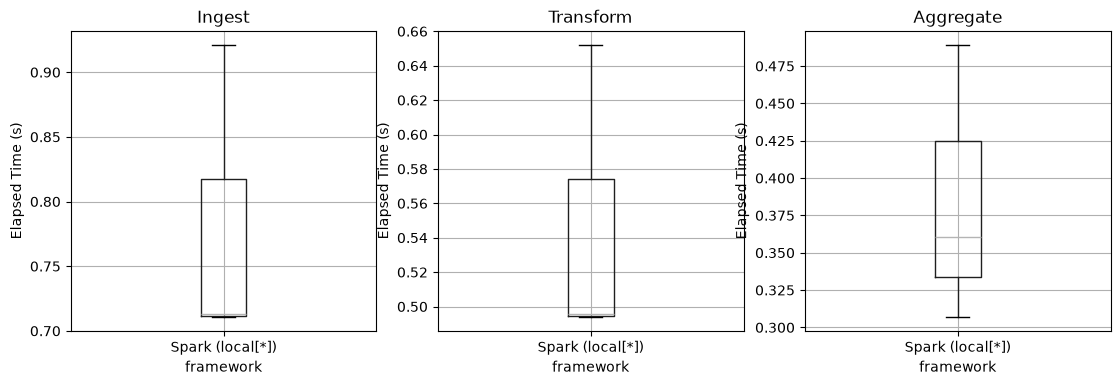

In [5]:
# one box per framework, one chart per benchmark
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, bench_df, title in zip(axes, [ingest_df, transform_df, aggregate_df], ["Ingest", "Transform", "Aggregate"]):
    timed = bench_df[bench_df["phase"] == "timed"]
    timed.boxplot(column="elapsed_s", by="framework", ax=ax)
    ax.set_ylabel("Elapsed Time (s)")
    ax.set_title(title)
plt.suptitle("")   # suppress pandas' auto title